In [1]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate our project folder
project_path = Path.cwd()

# Load the prepared dataset from Phase 1
data_path = project_path / "prepared_data" / "npp_prepared.csv"

df = pd.read_csv(data_path)

# Display dataset information
print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nClass distribution:")
print(df["Label"].value_counts())

print("\nNumber of scenarios:", df["Scenario_ID"].nunique())

display(df.head())


Dataset loaded successfully!

Dataset shape: (12152, 100)

Class distribution:
Label
1    11543
0      609
Name: count, dtype: int64

Number of scenarios: 20


,TIME,P,TAVG,THA,THB,TCA,TCB,WRCA,WRCB,PSGA,...,TCRT,TSLP,PPM,RRCA,RRCB,RRCO,WFLB,Scenario,Scenario_ID,Label
0,0,155.500015,310.000000,327.823975,327.823212,292.176056,292.176788,16515.818359,33031.636719,67.000031,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
1,1,155.494339,309.993713,327.823273,327.822479,292.175049,292.175842,16515.818359,33031.636719,66.999924,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
2,2,155.486084,309.987915,327.821381,327.820618,292.173492,292.174286,16515.818359,33031.636719,66.999176,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
3,3,155.478165,309.982910,327.818756,327.817932,292.171509,292.172272,16515.818359,33031.636719,66.997894,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0
4,4,155.471954,309.979370,327.815796,327.814972,292.169220,292.170013,16515.818359,33031.636719,66.996246,...,50,50.0,200.0,1.0,1.0,1.0,0,00 - Normal Operation,0,0


In [2]:

# Separate input features (X) and target labels (y)

# Columns that should not be used as model inputs
excluded_columns = [
    "TIME",
    "Scenario",
    "Scenario_ID",
    "Label"
]

# X contains only the 96 sensor measurements
X = df.drop(columns=excluded_columns)

# y contains the correct classification labels
y = df["Label"]

# Keep scenario IDs for later evaluation
groups = df["Scenario_ID"]

print("Feature matrix X:", X.shape)
print("Target vector y:", y.shape)

print("\nNumber of sensor features:", X.shape[1])

print("\nTarget classes:")
print(y.value_counts())

print("\nAll features numeric:",
      X.select_dtypes(include=np.number).shape[1] == X.shape[1])

print("\nFirst 10 feature names:")
print(X.columns[:10].tolist())


Feature matrix X: (12152, 96)
Target vector y: (12152,)

Number of sensor features: 96

Target classes:
Label
1    11543
0      609
Name: count, dtype: int64

All features numeric: True

First 10 feature names:
['P', 'TAVG', 'THA', 'THB', 'TCA', 'TCB', 'WRCA', 'WRCB', 'PSGA', 'PSGB']


In [3]:

# Chronological 80/20 split within each scenario

train_indices = []
test_indices = []

for scenario_id, scenario_data in df.groupby("Scenario_ID"):

    # Sort each scenario by simulation time
    scenario_data = scenario_data.sort_values("TIME")

    # Calculate the 80% split point
    split_point = int(len(scenario_data) * 0.8)

    # Assign earlier readings to training
    train_indices.extend(
        scenario_data.index[:split_point].tolist()
    )

    # Assign later readings to testing
    test_indices.extend(
        scenario_data.index[split_point:].tolist()
    )

# Create training and testing sets
X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

print("\nOverlapping indices:",
      len(set(train_indices) & set(test_indices)))


Training features: (9712, 96)
Testing features: (2440, 96)

Training label distribution:
Label
1    9225
0     487
Name: count, dtype: int64

Testing label distribution:
Label
1    2318
0     122
Name: count, dtype: int64

Overlapping indices: 0


In [4]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model using training data only
rf_model.fit(X_train, y_train)

# Predict using the testing data
rf_predictions = rf_model.predict(X_test)

# Evaluate model performance
print("Random Forest Results")
print("----------------------")

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, rf_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))


Random Forest Results
----------------------
Accuracy: 0.9459
Balanced Accuracy: 0.4978

Classification Report:
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       122
       Fault       0.95      1.00      0.97      2318

    accuracy                           0.95      2440
   macro avg       0.47      0.50      0.49      2440
weighted avg       0.90      0.95      0.92      2440


Confusion Matrix:
[[   0  122]
 [  10 2308]]


In [5]:

# Compare Random Forest training and testing performance

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# Generate training predictions
rf_train_predictions = rf_model.predict(X_train)

print("RANDOM FOREST - TRAINING PERFORMANCE")
print("------------------------------------")

print("Balanced Accuracy:",
      round(balanced_accuracy_score(
          y_train, rf_train_predictions
      ), 4))

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train, rf_train_predictions))

print("\nTraining Classification Report:")
print(classification_report(
    y_train,
    rf_train_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nRANDOM FOREST - TESTING PERFORMANCE")
print("------------------------------------")

print("Balanced Accuracy:",
      round(balanced_accuracy_score(
          y_test, rf_predictions
      ), 4))


RANDOM FOREST - TRAINING PERFORMANCE
------------------------------------
Balanced Accuracy: 0.9197

Training Confusion Matrix:
[[ 485    2]
 [1444 7781]]

Training Classification Report:
              precision    recall  f1-score   support

      Normal       0.25      1.00      0.40       487
       Fault       1.00      0.84      0.91      9225

    accuracy                           0.85      9712
   macro avg       0.63      0.92      0.66      9712
weighted avg       0.96      0.85      0.89      9712


RANDOM FOREST - TESTING PERFORMANCE
------------------------------------
Balanced Accuracy: 0.4978


In [6]:

# Compare normal-operation sensor measurements
# between training and testing datasets

normal_train = X_train[y_train == 0]
normal_test = X_test[y_test == 0]

selected_features = ["P", "TAVG", "WRCA"]

comparison = pd.DataFrame({
    "Train Mean": normal_train[selected_features].mean(),
    "Test Mean": normal_test[selected_features].mean(),
    "Train Std": normal_train[selected_features].std(),
    "Test Std": normal_test[selected_features].std(),
    "Train Min": normal_train[selected_features].min(),
    "Test Min": normal_test[selected_features].min(),
    "Train Max": normal_train[selected_features].max(),
    "Test Max": normal_test[selected_features].max()
})

print("Normal Operation: Training vs Testing")
display(comparison.round(4))


Normal Operation: Training vs Testing


,Train Mean,Test Mean,Train Std,Test Std,Train Min,Test Min,Train Max,Test Max
P,155.4965,155.5112,0.0110,0.0007,155.4664,155.5097,155.5096,155.5117
TAVG,309.9823,309.9824,0.0012,0.0000,309.9770,309.9824,310.0000,309.9824
WRCA,16515.8184,16515.8184,0.0000,0.0000,16515.8184,16515.8184,16515.8184,16515.8184


Top 15 Most Important Features:


,Feature,Importance
77,DWB,0.0809
76,DTHY,0.0771
66,RM2,0.0721
58,TFSB,0.0467
11,WFWB,0.0430
71,STRB,0.0416
10,WFWA,0.0380
56,PWNT,0.0373
70,RC131,0.0332
57,PWR,0.0322


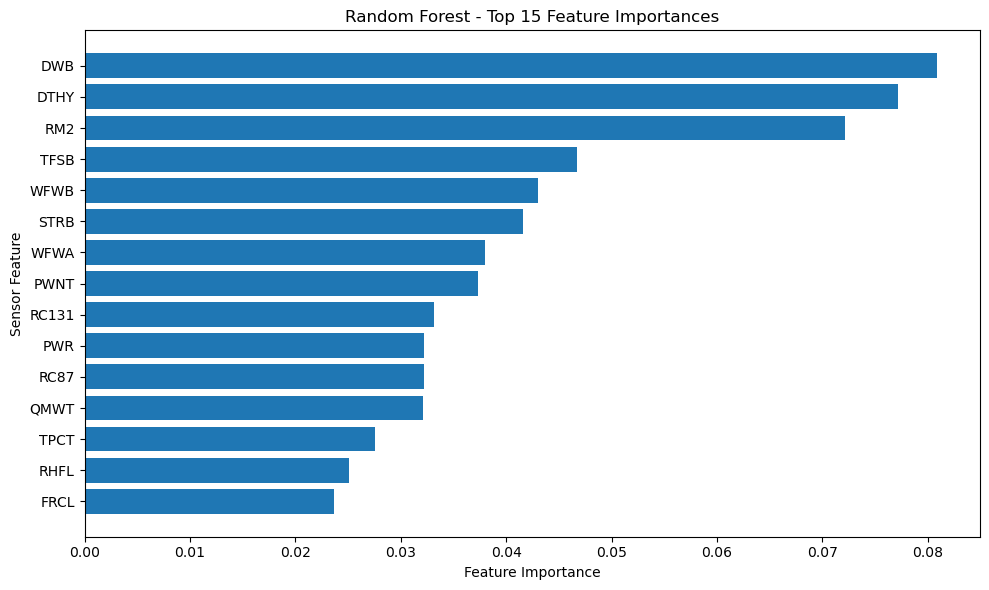

In [7]:

# Analyze Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Most Important Features:")
display(feature_importance.head(15).round(4))

# Plot the top 15 features
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Sensor Feature")
plt.tight_layout()

# Save figure for our final report
results_path = project_path / "results"
results_path.mkdir(exist_ok=True)

plt.savefig(
    results_path / "rf_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [8]:

from sklearn.utils import resample

# Separate normal and fault records from training data
normal_indices = y_train[y_train == 0].index
fault_indices = y_train[y_train == 1].index

# Randomly select the same number of fault records
balanced_fault_indices = resample(
    fault_indices,
    replace=False,
    n_samples=len(normal_indices),
    random_state=42
)

# Combine normal and selected fault records
balanced_indices = np.concatenate([
    normal_indices.to_numpy(),
    np.asarray(balanced_fault_indices)
])

# Create balanced training data
X_train_balanced = X_train.loc[balanced_indices]
y_train_balanced = y_train.loc[balanced_indices]

print("Balanced training distribution:")
print(y_train_balanced.value_counts())

# Train a new Random Forest
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_balanced, y_train_balanced)

# Evaluate on the ORIGINAL test set
rf_balanced_predictions = rf_balanced.predict(X_test)

print("\nBALANCED RANDOM FOREST RESULTS")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(
          y_test, rf_balanced_predictions
      ), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(
          y_test, rf_balanced_predictions
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_balanced_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_balanced_predictions
))


Balanced training distribution:
Label
0    487
1    487
Name: count, dtype: int64

BALANCED RANDOM FOREST RESULTS
------------------------------
Accuracy: 0.8508
Balanced Accuracy: 0.9215

Classification Report:
              precision    recall  f1-score   support

      Normal       0.25      1.00      0.40       122
       Fault       1.00      0.84      0.91      2318

    accuracy                           0.85      2440
   macro avg       0.63      0.92      0.66      2440
weighted avg       0.96      0.85      0.89      2440


Confusion Matrix:
[[ 122    0]
 [ 364 1954]]


Random Forest Model Comparison:


,Model,Accuracy,Balanced Accuracy,Normal Recall,Fault Recall
0,Original Random Forest,0.9459,0.4978,0.0,0.9957
1,Balanced Random Forest,0.8508,0.9215,1.0,0.8430


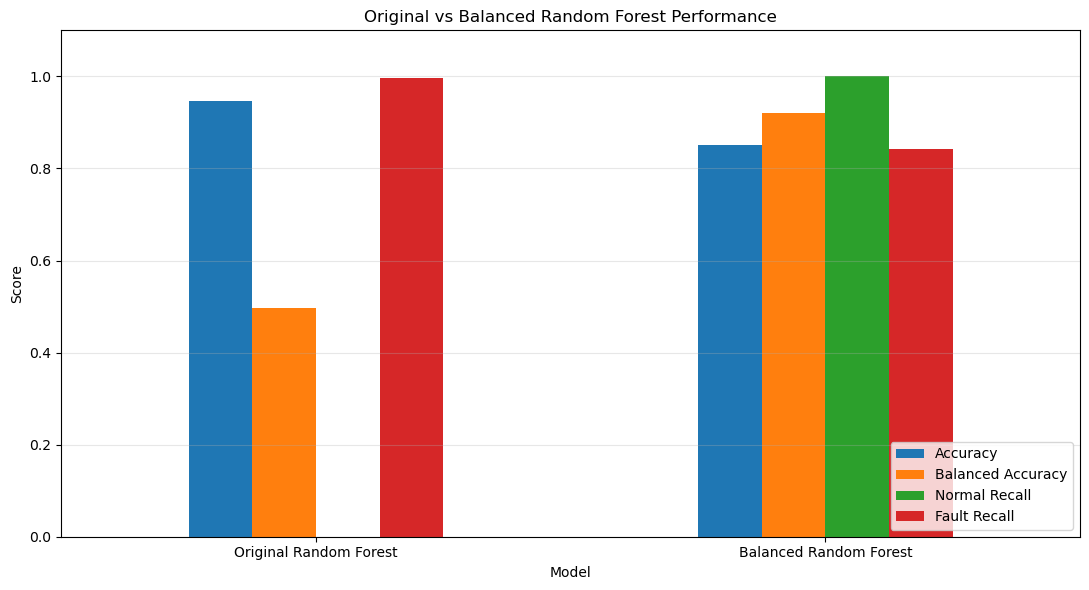

In [9]:

from sklearn.metrics import recall_score

# Calculate performance metrics for both models
model_comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Balanced Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, rf_balanced_predictions)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, rf_predictions),
        balanced_accuracy_score(y_test, rf_balanced_predictions)
    ],
    "Normal Recall": [
        recall_score(y_test, rf_predictions, pos_label=0),
        recall_score(y_test, rf_balanced_predictions, pos_label=0)
    ],
    "Fault Recall": [
        recall_score(y_test, rf_predictions, pos_label=1),
        recall_score(y_test, rf_balanced_predictions, pos_label=1)
    ]
})

print("Random Forest Model Comparison:")
display(model_comparison.round(4))

# Create comparison chart
comparison_plot = model_comparison.set_index("Model")

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Original vs Balanced Random Forest Performance")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

# Save for our final report
plt.savefig(
    results_path / "rf_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [10]:

# Check whether XGBoost is installed

try:
    import xgboost as xgb

    print("XGBoost is installed successfully!")
    print("Version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")
    print("Run the installation command below.")


XGBoost is installed successfully!
Version: 2.0.3


In [11]:

from xgboost import XGBClassifier

# Reverse labels so Normal becomes the positive class
y_train_xgb = 1 - y_train

# Calculate the imbalance ratio
normal_count = (y_train == 0).sum()
fault_count = (y_train == 1).sum()

weight_ratio = fault_count / normal_count

print("Class weight ratio:", round(weight_ratio, 2))

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=weight_ratio,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train XGBoost
xgb_model.fit(X_train, y_train_xgb)

# Predict and convert back to original labels
xgb_predictions = 1 - xgb_model.predict(X_test)

# Evaluate model performance
print("\nXGBOOST RESULTS")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, xgb_predictions), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, xgb_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))


Class weight ratio: 18.94

XGBOOST RESULTS
------------------------------
Accuracy: 0.8508
Balanced Accuracy: 0.9215

Classification Report:
              precision    recall  f1-score   support

      Normal       0.25      1.00      0.40       122
       Fault       1.00      0.84      0.91      2318

    accuracy                           0.85      2440
   macro avg       0.63      0.92      0.66      2440
weighted avg       0.96      0.85      0.89      2440


Confusion Matrix:
[[ 122    0]
 [ 364 1954]]


In [12]:

# Analyze XGBoost performance for each malfunction scenario

# Create a results table containing test predictions
error_df = df.loc[test_indices, [
    "Scenario",
    "Scenario_ID",
    "TIME",
    "Label"
]].copy()

error_df["Prediction"] = xgb_predictions

# Calculate correct and incorrect predictions
error_df["Correct"] = (
    error_df["Label"] == error_df["Prediction"]
)

# Calculate performance for each scenario
scenario_results = (
    error_df.groupby("Scenario")
    .agg(
        Total_Records=("Correct", "size"),
        Correct_Predictions=("Correct", "sum"),
        Accuracy=("Correct", "mean")
    )
    .reset_index()
)

scenario_results["Missed_Records"] = (
    scenario_results["Total_Records"] -
    scenario_results["Correct_Predictions"]
)

# Sort scenarios from worst to best
scenario_results = scenario_results.sort_values(
    by="Accuracy",
    ascending=True
)

print("XGBoost Performance by Scenario:")
display(scenario_results.round(4))


XGBoost Performance by Scenario:


,Scenario,Total_Records,Correct_Predictions,Accuracy,Missed_Records
5,05 - Spark Presence for Hydrogen Burn,121,0,0.0,121
13,14 - Moderator Dilution,122,0,0.0,122
8,08 - Anticipated Transient without Scram,121,0,0.0,121
0,00 - Normal Operation,122,122,1.0,0
17,18 - Fuel Handling Accident in Containment,122,122,1.0,0
16,17 - Fuel Failure at Power,122,122,1.0,0
15,16 - Containment Failure or Spark for H2 Deton...,124,124,1.0,0
14,15 - Load Rejection,124,124,1.0,0
12,12 - Rod withdrawal Insertion,121,121,1.0,0
11,11 - Steam Generator B Tube Rupture,122,122,1.0,0


In [13]:

# Investigate the three malfunction scenarios
# that XGBoost failed to detect

problem_scenarios = [5, 8, 14]
selected_sensors = ["P", "TAVG", "DWB"]

# Calculate normal-operation sensor averages
normal_reference = df[
    df["Scenario_ID"] == 0
][selected_sensors].mean()

comparison_results = []

for scenario_id in problem_scenarios:

    scenario_data = df[
        df["Scenario_ID"] == scenario_id
    ]

    scenario_means = scenario_data[
        selected_sensors
    ].mean()

    result = {
        "Scenario": scenario_data["Scenario"].iloc[0]
    }

    for sensor in selected_sensors:
        result[f"{sensor}_Mean"] = scenario_means[sensor]
        result[f"{sensor}_Difference"] = (
            scenario_means[sensor] -
            normal_reference[sensor]
        )

    comparison_results.append(result)

problem_comparison = pd.DataFrame(comparison_results)

print("Normal Operation Sensor Averages:")
display(normal_reference.round(4))

print("\nProblematic Scenario Comparison:")
display(problem_comparison.round(4))


Normal Operation Sensor Averages:


P       155.4995
TAVG    309.9823
DWB       0.0000
dtype: float64


Problematic Scenario Comparison:


,Scenario,P_Mean,P_Difference,TAVG_Mean,TAVG_Difference,DWB_Mean,DWB_Difference
0,05 - Spark Presence for Hydrogen Burn,155.4994,-0.0001,309.9823,-0.0,0.0,0.0
1,08 - Anticipated Transient without Scram,155.4994,-0.0001,309.9823,-0.0,0.0,0.0
2,14 - Moderator Dilution,155.4995,0.0000,309.9823,-0.0,0.0,0.0


In [14]:

# Compare all sensors in the three difficult scenarios
# against normal operation over the same test-time region

problem_scenarios = [5, 8, 14]

# Get normal operation readings from the test portion
normal_test_data = df.loc[
    test_indices
][df.loc[test_indices, "Scenario_ID"] == 0]

sensor_features = X.columns.tolist()

results = []

for scenario_id in problem_scenarios:

    # Get test readings for this fault scenario
    fault_test_data = df.loc[test_indices]
    fault_test_data = fault_test_data[
        fault_test_data["Scenario_ID"] == scenario_id
    ]

    # Compare average sensor readings
    normal_means = normal_test_data[sensor_features].mean()
    fault_means = fault_test_data[sensor_features].mean()

    # Calculate normal standard deviations
    normal_std = normal_test_data[sensor_features].std()

    # Standardized differences
    differences = (
        (fault_means - normal_means).abs() /
        normal_std.replace(0, np.nan)
    )

    # Find the top 5 most different sensors
    top_sensors = differences.dropna().nlargest(5)

    for sensor, difference in top_sensors.items():
        results.append({
            "Scenario_ID": scenario_id,
            "Sensor": sensor,
            "Standardized_Difference": difference
        })

sensor_difference_df = pd.DataFrame(results)

print("Top Sensor Differences for Difficult Scenarios:")
display(sensor_difference_df.round(4))


Top Sensor Differences for Difficult Scenarios:


,Scenario_ID,Sensor,Standardized_Difference
0,5,WECS,0.1623
1,5,WCHG,0.1623
2,5,LVPZ,0.1556
3,5,RBLK,0.1555
4,5,VOL,0.1551
5,8,WECS,0.1623
6,8,WCHG,0.1623
7,8,LVPZ,0.1556
8,8,RBLK,0.1555
9,8,VOL,0.1551


In [15]:

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Select only normal operation records for training
X_normal_train = X_train[y_train == 0]

# Scale sensor features using normal training data only
scaler = StandardScaler()
X_normal_scaled = scaler.fit_transform(X_normal_train)

# Apply the same scaling to the test set
X_test_scaled = scaler.transform(X_test)

# Create Isolation Forest
iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# Train using only normal data
iso_model.fit(X_normal_scaled)

# Predict anomalies
# Isolation Forest: 1 = Normal, -1 = Anomaly
iso_raw_predictions = iso_model.predict(X_test_scaled)

# Convert to our project labels
# 0 = Normal, 1 = Fault
iso_predictions = np.where(
    iso_raw_predictions == -1, 1, 0
)

# Evaluate model
print("ISOLATION FOREST RESULTS")
print("------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, iso_predictions), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, iso_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    iso_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, iso_predictions))


ISOLATION FOREST RESULTS
------------------------
Accuracy: 0.6004
Balanced Accuracy: 0.7897

Classification Report:
              precision    recall  f1-score   support

      Normal       0.11      1.00      0.20       122
       Fault       1.00      0.58      0.73      2318

    accuracy                           0.60      2440
   macro avg       0.56      0.79      0.47      2440
weighted avg       0.96      0.60      0.71      2440


Confusion Matrix:
[[ 122    0]
 [ 975 1343]]


In [16]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Store all models' predictions
model_predictions = {
    "Original Random Forest": rf_predictions,
    "Balanced Random Forest": rf_balanced_predictions,
    "XGBoost": xgb_predictions,
    "Isolation Forest": iso_predictions
}

# Calculate performance metrics
comparison_results = []

for model_name, predictions in model_predictions.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Normal Recall": recall_score(
            y_test, predictions, pos_label=0
        ),
        "Fault Recall": recall_score(
            y_test, predictions, pos_label=1
        ),
        "Missed Faults": int(
            ((y_test == 1) & (predictions == 0)).sum()
        ),
        "False Alarms": int(
            ((y_test == 0) & (predictions == 1)).sum()
        )
    })

# Create comparison table
final_comparison = pd.DataFrame(comparison_results)

print("PRELIMINARY MACHINE LEARNING MODEL COMPARISON")
display(final_comparison.round(4))

# Save results for our report
results_path = project_path / "results"
results_path.mkdir(exist_ok=True)

final_comparison.to_csv(
    results_path / "preliminary_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")


PRELIMINARY MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1,Normal Recall,Fault Recall,Missed Faults,False Alarms
0,Original Random Forest,0.9459,0.4978,0.4861,0.0,0.9957,10,122
1,Balanced Random Forest,0.8508,0.9215,0.6581,1.0,0.8430,364,0
2,XGBoost,0.8508,0.9215,0.6581,1.0,0.8430,364,0
3,Isolation Forest,0.6004,0.7897,0.4669,1.0,0.5794,975,0



Model comparison saved successfully!


In [17]:

# Phase 3 - Step 1
# Compare difficult scenarios against normal operation

problem_scenarios = [5, 8, 14]

normal_reference = df[df["Scenario_ID"] == 0].set_index("TIME")

comparison_results = []

for scenario_id in problem_scenarios:

    fault_data = df[
        df["Scenario_ID"] == scenario_id
    ].set_index("TIME")

    # Compare only matching simulation times
    common_times = normal_reference.index.intersection(
        fault_data.index
    )

    normal_values = normal_reference.loc[
        common_times, X.columns
    ].to_numpy(dtype=float)

    fault_values = fault_data.loc[
        common_times, X.columns
    ].to_numpy(dtype=float)

    # Compare all sensor measurements
    matches = np.isclose(
        normal_values,
        fault_values,
        rtol=1e-5,
        atol=1e-8
    )

    comparison_results.append({
        "Scenario_ID": scenario_id,
        "Compared_Rows": len(common_times),
        "Identical_Rows": int(matches.all(axis=1).sum()),
        "Matching_Sensor_Percentage": (
            matches.mean() * 100
        ),
        "Maximum_Absolute_Difference": float(
            np.abs(normal_values - fault_values).max()
        )
    })

duplicate_analysis = pd.DataFrame(comparison_results)

print("Difficult Scenario Similarity Analysis:")
display(duplicate_analysis.round(4))


Difficult Scenario Similarity Analysis:


,Scenario_ID,Compared_Rows,Identical_Rows,Matching_Sensor_Percentage,Maximum_Absolute_Difference
0,5,602,602,100.0,0.0
1,8,602,602,100.0,0.0
2,14,608,608,100.0,0.0


In [18]:

# Phase 3 - Step 2
# Create a revised dataset excluding indistinguishable scenarios

excluded_scenarios = [5, 8, 14]

revised_df = df[
    ~df["Scenario_ID"].isin(excluded_scenarios)
].copy()

revised_df.reset_index(drop=True, inplace=True)

print("Original dataset:", df.shape)
print("Revised dataset:", revised_df.shape)

print("\nRevised class distribution:")
print(revised_df["Label"].value_counts())

print("\nRemaining scenarios:",
      revised_df["Scenario_ID"].nunique())

# Save without modifying the original dataset
revised_df.to_csv(
    project_path / "prepared_data" / "npp_revised.csv",
    index=False
)

print("\nRevised dataset saved successfully!")


Original dataset: (12152, 100)
Revised dataset: (10339, 100)

Revised class distribution:
Label
1    9730
0     609
Name: count, dtype: int64

Remaining scenarios: 17

Revised dataset saved successfully!


In [19]:

# Phase 3 - Step 3
# Chronological Train / Validation / Test split

train_idx = []
val_idx = []
test_idx = []

for scenario_id, scenario_data in revised_df.groupby("Scenario_ID"):

    # Arrange measurements in time order
    scenario_data = scenario_data.sort_values("TIME")

    n = len(scenario_data)

    # Calculate split boundaries
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_idx.extend(scenario_data.index[:train_end])
    val_idx.extend(scenario_data.index[train_end:val_end])
    test_idx.extend(scenario_data.index[val_end:])

# Separate sensor features and labels
excluded_columns = ["TIME", "Scenario", "Scenario_ID", "Label"]

X_revised = revised_df.drop(columns=excluded_columns)
y_revised = revised_df["Label"]

# Create the three datasets
X_train_new = X_revised.loc[train_idx]
X_val_new = X_revised.loc[val_idx]
X_test_new = X_revised.loc[test_idx]

y_train_new = y_revised.loc[train_idx]
y_val_new = y_revised.loc[val_idx]
y_test_new = y_revised.loc[test_idx]

print("Training:", X_train_new.shape)
print("Validation:", X_val_new.shape)
print("Testing:", X_test_new.shape)

print("\nTraining labels:")
print(y_train_new.value_counts())

print("\nValidation labels:")
print(y_val_new.value_counts())

print("\nTesting labels:")
print(y_test_new.value_counts())

print("\nOverlapping indices:",
      len(
          (set(train_idx) & set(val_idx)) |
          (set(train_idx) & set(test_idx)) |
          (set(val_idx) & set(test_idx))
      ))


Training: (7230, 96)
Validation: (1548, 96)
Testing: (1561, 96)

Training labels:
Label
1    6804
0     426
Name: count, dtype: int64

Validation labels:
Label
1    1457
0      91
Name: count, dtype: int64

Testing labels:
Label
1    1469
0      92
Name: count, dtype: int64

Overlapping indices: 0


In [20]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score
)
from sklearn.utils import resample

# 1. Standard Random Forest
rf_standard_new = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_standard_new.fit(X_train_new, y_train_new)

# 2. Weighted Random Forest
rf_weighted_new = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_weighted_new.fit(X_train_new, y_train_new)

# 3. Balanced Random Forest using undersampling
normal_idx = y_train_new[y_train_new == 0].index
fault_idx = y_train_new[y_train_new == 1].index

sampled_fault_idx = resample(
    fault_idx,
    replace=False,
    n_samples=len(normal_idx),
    random_state=42
)

balanced_idx = np.concatenate([
    normal_idx.to_numpy(),
    np.asarray(sampled_fault_idx)
])

rf_balanced_new = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_balanced_new.fit(
    X_train_new.loc[balanced_idx],
    y_train_new.loc[balanced_idx]
)

# Compare the three models on validation data
rf_models = {
    "Standard RF": rf_standard_new,
    "Weighted RF": rf_weighted_new,
    "Balanced RF": rf_balanced_new
}

rf_results = []

for name, model in rf_models.items():

    predictions = model.predict(X_val_new)

    rf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_new, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val_new, predictions
        ),
        "Normal Recall": recall_score(
            y_val_new, predictions, pos_label=0
        ),
        "Fault Recall": recall_score(
            y_val_new, predictions, pos_label=1
        ),
        "Macro F1": f1_score(
            y_val_new, predictions, average="macro"
        )
    })

rf_validation_results = pd.DataFrame(rf_results)

print("REVISED RANDOM FOREST - VALIDATION RESULTS")
display(rf_validation_results.round(4))


REVISED RANDOM FOREST - VALIDATION RESULTS


,Model,Accuracy,Balanced Accuracy,Normal Recall,Fault Recall,Macro F1
0,Standard RF,1.0,1.0,1.0,1.0,1.0
1,Weighted RF,1.0,1.0,1.0,1.0,1.0
2,Balanced RF,1.0,1.0,1.0,1.0,1.0


In [21]:

# Phase 3 - Step 5
# Evaluate generalization to unseen malfunction scenarios

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Fault scenarios reserved for testing
held_out_scenarios = [1, 6, 9]

# Training: remaining fault scenarios + early normal readings
train_mask = (
    (~revised_df["Scenario_ID"].isin(held_out_scenarios)) &
    (
        (revised_df["Scenario_ID"] != 0) |
        (revised_df["TIME"] < 400)
    )
)

# Testing: held-out faults + later normal readings
test_mask = (
    (revised_df["Scenario_ID"].isin(held_out_scenarios)) |
    (
        (revised_df["Scenario_ID"] == 0) &
        (revised_df["TIME"] >= 400)
    )
)

X_scenario_train = X_revised.loc[train_mask]
y_scenario_train = y_revised.loc[train_mask]

X_scenario_test = X_revised.loc[test_mask]
y_scenario_test = y_revised.loc[test_mask]

# Train Random Forest
rf_scenario = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_scenario.fit(
    X_scenario_train,
    y_scenario_train
)

# Evaluate predictions
scenario_predictions = rf_scenario.predict(
    X_scenario_test
)

print("UNSEEN SCENARIO EXPERIMENT")
print("--------------------------")

print("Training records:", len(X_scenario_train))
print("Testing records:", len(X_scenario_test))

print("\nBalanced Accuracy:",
      round(balanced_accuracy_score(
          y_scenario_test,
          scenario_predictions
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_scenario_test,
    scenario_predictions,
    target_names=["Normal", "Fault"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_scenario_test,
    scenario_predictions
))


UNSEEN SCENARIO EXPERIMENT
--------------------------
Training records: 8287
Testing records: 2052

Balanced Accuracy: 0.4997

Classification Report:
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       209
       Fault       0.90      1.00      0.95      1843

    accuracy                           0.90      2052
   macro avg       0.45      0.50      0.47      2052
weighted avg       0.81      0.90      0.85      2052


Confusion Matrix:
[[   0  209]
 [   1 1842]]


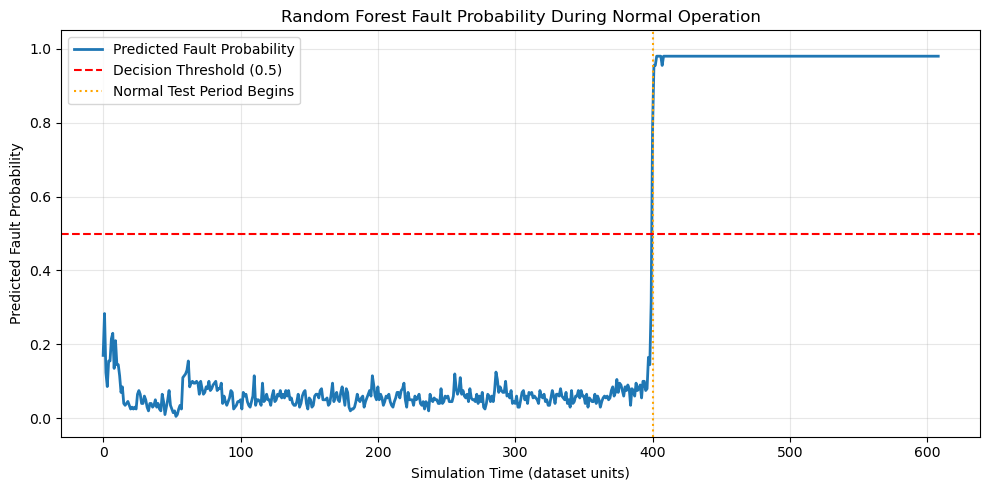

Normal training-period average fault probability: 0.0624
Normal test-period average fault probability: 0.9787


In [22]:

# Investigate Random Forest predictions over normal-operation time

normal_full = revised_df[
    revised_df["Scenario_ID"] == 0
].sort_values("TIME").copy()

# Extract the same 96 sensor features
X_normal_full = normal_full[X_revised.columns]

# Get predicted probability of Fault (class 1)
normal_full["Fault_Probability"] = (
    rf_scenario.predict_proba(X_normal_full)[:, 1]
)

# Plot fault probability over time
plt.figure(figsize=(10, 5))

plt.plot(
    normal_full["TIME"],
    normal_full["Fault_Probability"],
    linewidth=2,
    label="Predicted Fault Probability"
)

plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Decision Threshold (0.5)"
)

plt.axvline(
    x=400,
    color="orange",
    linestyle=":",
    label="Normal Test Period Begins"
)

plt.title("Random Forest Fault Probability During Normal Operation")
plt.xlabel("Simulation Time (dataset units)")
plt.ylabel("Predicted Fault Probability")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_path / "normal_fault_probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Normal training-period average fault probability:",
      round(normal_full.loc[
          normal_full["TIME"] < 400,
          "Fault_Probability"
      ].mean(), 4))

print("Normal test-period average fault probability:",
      round(normal_full.loc[
          normal_full["TIME"] >= 400,
          "Fault_Probability"
      ].mean(), 4))


In [23]:

# Investigate changes in normal-operation sensors
# around the model's prediction jump

normal_sorted = normal_full.set_index("TIME")

# Compare sensor measurements at time 399 and 400
before = normal_sorted.loc[399, X_revised.columns]
after = normal_sorted.loc[400, X_revised.columns]

# Calculate absolute changes
sensor_changes = (
    after.astype(float) - before.astype(float)
).abs()

# Calculate percentage changes where possible
percentage_changes = (
    sensor_changes /
    before.astype(float).abs().replace(0, np.nan)
) * 100

# Create a comparison table
change_analysis = pd.DataFrame({
    "Time_399": before.astype(float),
    "Time_400": after.astype(float),
    "Absolute_Change": sensor_changes,
    "Percentage_Change": percentage_changes
})

# Show the 15 largest absolute changes
change_analysis = change_analysis.sort_values(
    "Absolute_Change",
    ascending=False
)

print("Top 15 Sensor Changes Between Time 399 and 400:")
display(change_analysis.head(15).round(6))


Top 15 Sensor Changes Between Time 399 and 400:


,Time_399,Time_400,Absolute_Change,Percentage_Change
RBLK,532.780151,534.113770,1.333618,0.250313
WFWB,3831.294922,3831.296143,0.001221,0.000032
WFWA,1915.705933,1915.706299,0.000366,0.000019
WCHG,23.699755,23.699486,0.000269,0.001135
WECS,23.699755,23.699486,0.000269,0.001135
QMGB,1942.030273,1942.030396,0.000122,0.000006
LVPZ,61.997955,61.998020,0.000065,0.000105
QMGA,971.064758,971.064819,0.000061,0.000006
NSGB,50.004089,50.004032,0.000057,0.000114
NSGA,50.004078,50.004028,0.000050,0.000099


In [24]:

# Phase 3 - Step 8
# Investigate which sensor changes influence the model prediction

# Get normal-operation records at times 399 and 400
sample_399 = normal_sorted.loc[
    [399], X_revised.columns
].copy()

sample_400 = normal_sorted.loc[
    [400], X_revised.columns
].copy()

# Get original fault probabilities
prob_399 = rf_scenario.predict_proba(sample_399)[0, 1]
prob_400 = rf_scenario.predict_proba(sample_400)[0, 1]

print("Fault probability at time 399:", round(prob_399, 4))
print("Fault probability at time 400:", round(prob_400, 4))

# Test the effect of changing one sensor at a time
sensitivity_results = []

for sensor in X_revised.columns:

    modified_sample = sample_399.copy()

    # Replace one sensor with its time-400 value
    modified_sample[sensor] = sample_400[sensor].iloc[0]

    # Calculate the new predicted fault probability
    new_probability = rf_scenario.predict_proba(
        modified_sample
    )[0, 1]

    sensitivity_results.append({
        "Sensor": sensor,
        "Original_Probability": prob_399,
        "Modified_Probability": new_probability,
        "Probability_Change": new_probability - prob_399
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

# Rank by magnitude of probability change
sensitivity_df["Absolute_Effect"] = (
    sensitivity_df["Probability_Change"].abs()
)

sensitivity_df = sensitivity_df.sort_values(
    "Absolute_Effect",
    ascending=False
)

print("\nTop 15 Sensors Affecting the Prediction:")
display(sensitivity_df.head(15).round(4))


Fault probability at time 399: 0.315
Fault probability at time 400: 0.785

Top 15 Sensors Affecting the Prediction:


,Sensor,Original_Probability,Modified_Probability,Probability_Change,Absolute_Effect
74,RBLK,0.315,0.470,0.155,0.155
0,P,0.315,0.415,0.100,0.100
15,LVPZ,0.315,0.410,0.095,0.095
14,VOL,0.315,0.375,0.060,0.060
64,WCHG,0.315,0.340,0.025,0.025
29,NSGB,0.315,0.330,0.015,0.015
26,QMGA,0.315,0.325,0.010,0.010
22,WECS,0.315,0.325,0.010,0.010
28,NSGA,0.315,0.320,0.005,0.005
24,LSGA,0.315,0.320,0.005,0.005


In [25]:

# Phase 3 - Step 9
# Investigate sensitivity to the normal training boundary

training_boundaries = [250, 350, 450]

boundary_results = []

for boundary in training_boundaries:

    # Training: known fault scenarios + early normal data
    train_mask = (
        ~revised_df["Scenario_ID"].isin(held_out_scenarios)
    ) & (
        (revised_df["Scenario_ID"] != 0) |
        (revised_df["TIME"] < boundary)
    )

    # Testing: later normal readings + held-out faults
    test_mask = (
        revised_df["Scenario_ID"].isin(held_out_scenarios)
    ) | (
        (revised_df["Scenario_ID"] == 0) &
        (revised_df["TIME"] >= boundary)
    )

    # Prepare datasets
    X_boundary_train = X_revised.loc[train_mask]
    y_boundary_train = y_revised.loc[train_mask]

    X_boundary_test = X_revised.loc[test_mask]
    y_boundary_test = y_revised.loc[test_mask]

    # Train Random Forest
    model = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_boundary_train, y_boundary_train)

    predictions = model.predict(X_boundary_test)

    # Save evaluation results
    boundary_results.append({
        "Training_Boundary": boundary,
        "Balanced_Accuracy": balanced_accuracy_score(
            y_boundary_test, predictions
        ),
        "Normal_Recall": recall_score(
            y_boundary_test, predictions, pos_label=0
        ),
        "Fault_Recall": recall_score(
            y_boundary_test, predictions, pos_label=1
        )
    })

boundary_df = pd.DataFrame(boundary_results)

print("Training Boundary Sensitivity Analysis:")
display(boundary_df.round(4))


Training Boundary Sensitivity Analysis:


,Training_Boundary,Balanced_Accuracy,Normal_Recall,Fault_Recall
0,250,0.4997,0.0,0.9995
1,350,0.4997,0.0,0.9995
2,450,0.4997,0.0,0.9995


In [26]:

# Phase 3 - Step 10
# Check duplicated sensor measurements across scenarios

# Use only the 96 sensor features
sensor_data = revised_df[X_revised.columns]

# Count identical sensor records across the dataset
duplicate_count = sensor_data.duplicated(keep=False).sum()

print("Total records:", len(sensor_data))
print("Records involved in exact duplicates:", duplicate_count)

# Count unique sensor patterns
unique_patterns = sensor_data.drop_duplicates().shape[0]

print("Unique sensor patterns:", unique_patterns)

# Check how many sensor patterns have conflicting labels
duplicate_check = revised_df.copy()

duplicate_check["Sensor_Pattern"] = pd.util.hash_pandas_object(
    duplicate_check[X_revised.columns],
    index=False
)

conflicting_patterns = (
    duplicate_check.groupby("Sensor_Pattern")["Label"]
    .nunique()
)

print(
    "Sensor patterns with conflicting labels:",
    (conflicting_patterns > 1).sum()
)


Total records: 10339
Records involved in exact duplicates: 3
Unique sensor patterns: 10337
Sensor patterns with conflicting labels: 1


In [27]:

# Phase 3 - Step 11
# Identify duplicated sensor records and conflicting labels

# Find all records sharing identical sensor measurements
duplicate_mask = revised_df[
    X_revised.columns
].duplicated(keep=False)

duplicate_records = revised_df.loc[
    duplicate_mask,
    ["Scenario", "Scenario_ID", "TIME", "Label"]
].copy()

# Add a sensor pattern identifier for comparison
duplicate_records["Sensor_Pattern"] = (
    pd.util.hash_pandas_object(
        revised_df.loc[
            duplicate_mask, X_revised.columns
        ],
        index=False
    ).values
)

print("Duplicate Sensor Records:")
display(
    duplicate_records.sort_values(
        "Sensor_Pattern"
    )
)

print("\nNumber of duplicate records:",
      len(duplicate_records))


Duplicate Sensor Records:


,Scenario,Scenario_ID,TIME,Label,Sensor_Pattern
1,00 - Normal Operation,0,1,0,17075049062529779737
3020,06 - Loss of AC Power,6,1,1,17075049062529779737
6677,15 - Load Rejection,15,1,1,17075049062529779737



Number of duplicate records: 3


In [28]:

# Phase 3 - Step 12
# Scenario-based 4-fold cross-validation

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score
)

# Separate normal and fault scenarios
normal_mask = revised_df["Scenario_ID"] == 0
fault_mask = revised_df["Scenario_ID"] != 0

# Normal data: early period for training, later period for testing
normal_train_idx = revised_df.index[
    normal_mask & (revised_df["TIME"] < 400)
]

normal_test_idx = revised_df.index[
    normal_mask & (revised_df["TIME"] >= 400)
]

# Fault data for group-based splitting
fault_indices = revised_df.index[fault_mask]

fault_groups = revised_df.loc[
    fault_indices, "Scenario_ID"
]

# Create four scenario-based folds
gkf = GroupKFold(n_splits=4)

cv_results = []

for fold, (train_pos, test_pos) in enumerate(
    gkf.split(
        X_revised.loc[fault_indices],
        y_revised.loc[fault_indices],
        groups=fault_groups
    ),
    start=1
):

    # Fault scenarios assigned to this fold
    fault_train_idx = fault_indices[train_pos]
    fault_test_idx = fault_indices[test_pos]

    # Combine normal and fault records
    fold_train_idx = np.concatenate([
        normal_train_idx,
        fault_train_idx
    ])

    fold_test_idx = np.concatenate([
        normal_test_idx,
        fault_test_idx
    ])

    # Train a new model for each fold
    cv_model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    cv_model.fit(
        X_revised.loc[fold_train_idx],
        y_revised.loc[fold_train_idx]
    )

    # Evaluate on unseen fault scenarios
    predictions = cv_model.predict(
        X_revised.loc[fold_test_idx]
    )

    actual = y_revised.loc[fold_test_idx]

    cv_results.append({
        "Fold": fold,
        "Held_Out_Scenarios": sorted(
            revised_df.loc[
                fault_test_idx, "Scenario_ID"
            ].unique().tolist()
        ),
        "Accuracy": accuracy_score(actual, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(
            actual, predictions
        ),
        "Normal_Recall": recall_score(
            actual, predictions, pos_label=0
        ),
        "Fault_Recall": recall_score(
            actual, predictions, pos_label=1
        ),
        "Macro_F1": f1_score(
            actual, predictions, average="macro"
        )
    })

# Display results
cv_results_df = pd.DataFrame(cv_results)

print("SCENARIO-BASED CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

print("\nAVERAGE PERFORMANCE")
print(
    cv_results_df[
        ["Accuracy", "Balanced_Accuracy",
         "Normal_Recall", "Fault_Recall", "Macro_F1"]
    ].mean().round(4)
)

print("\nSTANDARD DEVIATION")
print(
    cv_results_df[
        ["Accuracy", "Balanced_Accuracy",
         "Normal_Recall", "Fault_Recall", "Macro_F1"]
    ].std().round(4)
)

# Save for the final report
cv_results_df.to_csv(
    results_path / "scenario_cross_validation.csv",
    index=False
)

print("\nCross-validation results saved!")


SCENARIO-BASED CROSS-VALIDATION RESULTS


,Fold,Held_Out_Scenarios,Accuracy,Balanced_Accuracy,Normal_Recall,Fault_Recall,Macro_F1
0,1,"[2, 6, 10, 11]",0.9209,0.4998,0.0,0.9996,0.4794
1,2,"[4, 7, 12, 15]",0.7757,0.4212,0.0,0.8424,0.4368
2,3,"[1, 3, 16, 17]",0.7238,0.3930,0.0,0.7860,0.4199
3,4,"[9, 18, 19, 20]",0.9206,0.5000,0.0,1.0000,0.4793



AVERAGE PERFORMANCE
Accuracy             0.8352
Balanced_Accuracy    0.4535
Normal_Recall        0.0000
Fault_Recall         0.9070
Macro_F1             0.4539
dtype: float64

STANDARD DEVIATION
Accuracy             0.1010
Balanced_Accuracy    0.0548
Normal_Recall        0.0000
Fault_Recall         0.1096
Macro_F1             0.0303
dtype: float64

Cross-validation results saved!


In [29]:

# Phase 3 - Step 13
# Compare Random Forest and XGBoost using scenario-based CV

from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score
)

gkf = GroupKFold(n_splits=4)

comparison_results = []

for fold, (train_pos, test_pos) in enumerate(
    gkf.split(
        X_revised.loc[fault_indices],
        y_revised.loc[fault_indices],
        groups=fault_groups
    ),
    start=1
):

    fault_train_idx = fault_indices[train_pos]
    fault_test_idx = fault_indices[test_pos]

    fold_train_idx = np.concatenate([
        normal_train_idx,
        fault_train_idx
    ])

    fold_test_idx = np.concatenate([
        normal_test_idx,
        fault_test_idx
    ])

    X_fold_train = X_revised.loc[fold_train_idx]
    y_fold_train = y_revised.loc[fold_train_idx]

    X_fold_test = X_revised.loc[fold_test_idx]
    y_fold_test = y_revised.loc[fold_test_idx]

    # Random Forest
    rf_cv = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_cv.fit(X_fold_train, y_fold_train)

    # XGBoost
    xgb_cv = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    # Keep original target labels: 0=Normal, 1=Fault
    xgb_cv.fit(X_fold_train, y_fold_train)

    models = {
        "Random Forest": rf_cv,
        "XGBoost": xgb_cv
    }

    for model_name, model in models.items():

        predictions = model.predict(X_fold_test)

        comparison_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_fold_test, predictions
            ),
            "Balanced_Accuracy": balanced_accuracy_score(
                y_fold_test, predictions
            ),
            "Normal_Recall": recall_score(
                y_fold_test, predictions, pos_label=0
            ),
            "Fault_Recall": recall_score(
                y_fold_test, predictions, pos_label=1
            ),
            "Macro_F1": f1_score(
                y_fold_test, predictions, average="macro"
            )
        })

# Show all results
cv_model_comparison = pd.DataFrame(comparison_results)

print("SCENARIO-BASED MODEL COMPARISON")
display(cv_model_comparison.round(4))

print("\nAVERAGE PERFORMANCE BY MODEL")
display(
    cv_model_comparison.groupby("Model")[
        ["Accuracy", "Balanced_Accuracy",
         "Normal_Recall", "Fault_Recall", "Macro_F1"]
    ].mean().round(4)
)

# Save results
cv_model_comparison.to_csv(
    results_path / "rf_xgboost_scenario_cv.csv",
    index=False
)

print("\nResults saved successfully!")


SCENARIO-BASED MODEL COMPARISON


,Fold,Model,Accuracy,Balanced_Accuracy,Normal_Recall,Fault_Recall,Macro_F1
0,1,Random Forest,0.9209,0.4998,0.0000,0.9996,0.4794
1,1,XGBoost,0.9996,0.9998,1.0000,0.9996,0.9987
2,2,Random Forest,0.7757,0.4212,0.0000,0.8424,0.4368
3,2,XGBoost,0.7901,0.4399,0.0239,0.8560,0.4501
4,3,Random Forest,0.7238,0.3930,0.0000,0.7860,0.4199
5,3,XGBoost,0.7700,0.8751,1.0000,0.7502,0.6325
6,4,Random Forest,0.9206,0.5000,0.0000,1.0000,0.4793
7,4,XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000



AVERAGE PERFORMANCE BY MODEL


,Accuracy,Balanced_Accuracy,Normal_Recall,Fault_Recall,Macro_F1
Model,,,,,
Random Forest,0.8352,0.4535,0.000,0.9070,0.4539
XGBoost,0.8899,0.8287,0.756,0.9014,0.7703



Results saved successfully!


In [30]:

# Phase 3 - Step 14
# Statistical comparison of Random Forest and XGBoost

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Arrange models side by side by fold
paired_results = cv_model_comparison.pivot(
    index="Fold",
    columns="Model",
    values="Balanced_Accuracy"
)

# Calculate differences in balanced accuracy
paired_results["Difference"] = (
    paired_results["XGBoost"] -
    paired_results["Random Forest"]
)

print("PAIRED MODEL COMPARISON")
display(paired_results.round(4))

# Calculate descriptive statistics
print("\nMean improvement:",
      round(paired_results["Difference"].mean(), 4))

print("Standard deviation of improvements:",
      round(paired_results["Difference"].std(), 4))

# Exploratory Wilcoxon signed-rank test
statistic, p_value = wilcoxon(
    paired_results["XGBoost"],
    paired_results["Random Forest"],
    alternative="greater",
    method="exact"
)

print("\nEXPLORATORY WILCOXON TEST")
print("Statistic:", statistic)
print("P-value:", round(p_value, 4))

print("\nInterpretation:")

if p_value < 0.05:
    print("The test shows a statistically significant difference.")
else:
    print("The test does not show a statistically significant difference.")

print(
    "\nNote: Fold results are not fully independent. "
    "This p-value should not be treated as confirmatory evidence."
)

# Save results
paired_results.to_csv(
    results_path / "statistical_model_comparison.csv"
)

print("\nStatistical comparison saved!")


PAIRED MODEL COMPARISON


Model,Random Forest,XGBoost,Difference
Fold,,,
1,0.4998,0.9998,0.5000
2,0.4212,0.4399,0.0188
3,0.3930,0.8751,0.4821
4,0.5000,1.0000,0.5000



Mean improvement: 0.3752
Standard deviation of improvements: 0.2378

EXPLORATORY WILCOXON TEST
Statistic: 10.0
P-value: 0.0625

Interpretation:
The test does not show a statistically significant difference.

Note: Fold results are not fully independent. This p-value should not be treated as confirmatory evidence.

Statistical comparison saved!


In [31]:

# Phase 3 - Step 15
# Feature ablation study using XGBoost

from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    f1_score
)

feature_counts = [96, 30, 15, 5]

ablation_results = []

gkf = GroupKFold(n_splits=4)

for fold, (train_pos, test_pos) in enumerate(
    gkf.split(
        X_revised.loc[fault_indices],
        y_revised.loc[fault_indices],
        groups=fault_groups
    ),
    start=1
):

    # Create scenario-based training and testing indices
    fault_train_idx = fault_indices[train_pos]
    fault_test_idx = fault_indices[test_pos]

    fold_train_idx = np.concatenate([
        normal_train_idx,
        fault_train_idx
    ])

    fold_test_idx = np.concatenate([
        normal_test_idx,
        fault_test_idx
    ])

    X_fold_train = X_revised.loc[fold_train_idx]
    y_fold_train = y_revised.loc[fold_train_idx]

    X_fold_test = X_revised.loc[fold_test_idx]
    y_fold_test = y_revised.loc[fold_test_idx]

    # Train a reference model using all features
    reference_model = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    reference_model.fit(X_fold_train, y_fold_train)

    # Rank features using training data only
    feature_ranking = pd.Series(
        reference_model.feature_importances_,
        index=X_fold_train.columns
    ).sort_values(ascending=False)

    for n_features in feature_counts:

        selected_features = feature_ranking.head(
            n_features
        ).index.tolist()

        # Train XGBoost using selected features
        model = XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_fold_train[selected_features],
            y_fold_train
        )

        predictions = model.predict(
            X_fold_test[selected_features]
        )

        ablation_results.append({
            "Fold": fold,
            "Features": n_features,
            "Balanced_Accuracy": balanced_accuracy_score(
                y_fold_test, predictions
            ),
            "Normal_Recall": recall_score(
                y_fold_test, predictions, pos_label=0
            ),
            "Fault_Recall": recall_score(
                y_fold_test, predictions, pos_label=1
            ),
            "Macro_F1": f1_score(
                y_fold_test, predictions, average="macro"
            )
        })

# Create summary tables
ablation_df = pd.DataFrame(ablation_results)

print("FEATURE ABLATION - ALL FOLDS")
display(ablation_df.round(4))

print("\nAVERAGE PERFORMANCE BY FEATURE COUNT")
ablation_summary = (
    ablation_df.groupby("Features")[
        ["Balanced_Accuracy", "Normal_Recall",
         "Fault_Recall", "Macro_F1"]
    ].mean()
)

display(ablation_summary.round(4))

# Save results
ablation_df.to_csv(
    results_path / "feature_ablation_results.csv",
    index=False
)

print("\nAblation study saved successfully!")


FEATURE ABLATION - ALL FOLDS


,Fold,Features,Balanced_Accuracy,Normal_Recall,Fault_Recall,Macro_F1
0,1,96,0.9998,1.0000,0.9996,0.9987
1,1,30,0.9998,1.0000,0.9996,0.9987
2,1,15,0.9998,1.0000,0.9996,0.9987
3,1,5,0.5000,0.0000,1.0000,0.4795
4,2,96,0.4399,0.0239,0.8560,0.4501
5,2,30,0.4399,0.0239,0.8560,0.4501
6,2,15,0.4399,0.0239,0.8560,0.4501
7,2,5,0.4495,0.0431,0.8560,0.4575
8,3,96,0.8751,1.0000,0.7502,0.6325
9,3,30,0.8751,1.0000,0.7502,0.6325



AVERAGE PERFORMANCE BY FEATURE COUNT


,Balanced_Accuracy,Normal_Recall,Fault_Recall,Macro_F1
Features,,,,
5,0.7061,0.5108,0.9013,0.6422
15,0.8287,0.7560,0.9014,0.7703
30,0.8287,0.7560,0.9014,0.7703
96,0.8287,0.7560,0.9014,0.7703



Ablation study saved successfully!


In [32]:

# Phase 3 - Step 16
# XGBoost hyperparameter tuning using validation data

from xgboost import XGBClassifier
from sklearn.metrics import balanced_accuracy_score, recall_score
from itertools import product

# Define a small parameter search
parameter_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

tuning_results = []

for n_estimators, max_depth, learning_rate in product(
    parameter_grid["n_estimators"],
    parameter_grid["max_depth"],
    parameter_grid["learning_rate"]
):

    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    # Train on the revised training set
    model.fit(X_train_new, y_train_new)

    # Evaluate on validation data only
    predictions = model.predict(X_val_new)

    tuning_results.append({
        "Estimators": n_estimators,
        "Max_Depth": max_depth,
        "Learning_Rate": learning_rate,
        "Balanced_Accuracy": balanced_accuracy_score(
            y_val_new, predictions
        ),
        "Normal_Recall": recall_score(
            y_val_new, predictions, pos_label=0
        ),
        "Fault_Recall": recall_score(
            y_val_new, predictions, pos_label=1
        )
    })

# Organize and rank results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by=["Balanced_Accuracy", "Fault_Recall"],
    ascending=False
)

print("XGBOOST HYPERPARAMETER TUNING RESULTS")
display(tuning_df.round(4))

# Save tuning results
tuning_df.to_csv(
    results_path / "xgboost_hyperparameter_tuning.csv",
    index=False
)

print("\nHyperparameter tuning results saved!")


XGBOOST HYPERPARAMETER TUNING RESULTS


,Estimators,Max_Depth,Learning_Rate,Balanced_Accuracy,Normal_Recall,Fault_Recall
0,100,3,0.05,1.0,1.0,1.0
1,100,3,0.10,1.0,1.0,1.0
2,100,5,0.05,1.0,1.0,1.0
3,100,5,0.10,1.0,1.0,1.0
4,200,3,0.05,1.0,1.0,1.0
5,200,3,0.10,1.0,1.0,1.0
6,200,5,0.05,1.0,1.0,1.0
7,200,5,0.10,1.0,1.0,1.0



Hyperparameter tuning results saved!


In [33]:

# Phase 3 - Step 17
# Train and save the demonstration XGBoost model

from xgboost import XGBClassifier
from pathlib import Path
import joblib
import json

# Create model output directory
models_path = project_path / "models"
models_path.mkdir(exist_ok=True)

# Use the revised dataset and all 96 sensor features
X_demo = X_revised.copy()
y_demo = y_revised.copy()

# Final demonstration configuration
demo_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model for demonstration
demo_model.fit(X_demo, y_demo)

# Save trained model
joblib.dump(
    demo_model,
    models_path / "npp_xgboost_model.joblib"
)

# Save exact feature order
feature_names = X_demo.columns.tolist()

with open(
    models_path / "feature_names.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(feature_names, file, indent=4)

# Verify saved files
print("Demonstration model saved successfully!")
print("Number of features:", len(feature_names))

print("\nModel files:")
for file in models_path.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


Demonstration model saved successfully!
Number of features: 96

Model files:
feature_names.json - 1.19 KB
npp_xgboost_model.joblib - 95.4 KB


In [34]:

# Check whether Streamlit is installed

import importlib.util

if importlib.util.find_spec("streamlit") is not None:
    import streamlit as st
    print("Streamlit is installed!")
    print("Version:", st.__version__)
else:
    print("Streamlit is not installed.")


Streamlit is installed!
Version: 1.32.0
